In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/ProyectoM1_MauricioVazquez/base_datos_restaurantes_USA_v2.csv')

df.head()
df.shape
df.info()
df.dtypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_persona                 30000 non-null  int64  
 1   nombre                     30000 non-null  object 
 2   apellido                   30000 non-null  object 
 3   edad                       29899 non-null  float64
 4   genero                     30000 non-null  object 
 5   ciudad_residencia          30000 non-null  object 
 6   estrato_socioeconomico     30000 non-null  object 
 7   frecuencia_visita          30000 non-null  int64  
 8   promedio_gasto_comida      29855 non-null  float64
 9   ocio                       30000 non-null  object 
 10  consume_licor              30000 non-null  object 
 11  preferencias_alimenticias  28597 non-null  object 
 12  membresia_premium          30000 non-null  object 
 13  telefono_contacto          14834 non-null  obj

,0
id_persona,int64
nombre,object
apellido,object
edad,float64
genero,object
ciudad_residencia,object
estrato_socioeconomico,object
frecuencia_visita,int64
promedio_gasto_comida,float64
ocio,object


In [ ]:
df['ciudad_residencia'] = df['ciudad_residencia'].str.strip().str.lower()
df['ciudad_residencia'].unique()
df['ciudad_residencia'].value_counts()

,count
ciudad_residencia,
chicago,5384
nyc,4769
miami,3186
san diego,3075
dallas,2602
boston,2547
denver,2523
houston,2212
seattle,2191


In [ ]:
df['ciudad_residencia'] = df['ciudad_residencia'].replace({'Nyc': 'New York'})
df['ciudad_residencia'].unique()
df['ciudad_residencia'].value_counts()

,count
ciudad_residencia,
chicago,5384
nyc,4769
miami,3186
san diego,3075
dallas,2602
boston,2547
denver,2523
houston,2212
seattle,2191


In [ ]:
ciudad_objetivo = 'Miami'

df_ciudad = df[df['ciudad_residencia'] == ciudad_objetivo].copy()

print(df_ciudad.shape)
print(df_ciudad['ciudad_residencia'].unique())
df_ciudad.head()

(0, 17)
[]


,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales


In [ ]:
df_ciudad.isnull().sum()
df_ciudad.isnull().mean() * 100

,0
id_persona,NaN
nombre,NaN
apellido,NaN
edad,NaN
genero,NaN
ciudad_residencia,NaN
estrato_socioeconomico,NaN
frecuencia_visita,NaN
promedio_gasto_comida,NaN
ocio,NaN


In [ ]:
df_ciudad['edad'] = df_ciudad['edad'].fillna(df_ciudad['edad'].median())
df_ciudad['promedio_gasto_comida'] = df_ciudad['promedio_gasto_comida'].fillna(df_ciudad['promedio_gasto_comida'].median())
df_ciudad['preferencias_alimenticias'] = df_ciudad['preferencias_alimenticias'].fillna('No especificado')
df_ciudad['telefono_contacto'] = df_ciudad['telefono_contacto'].fillna('No disponible')
df_ciudad['correo_electronico'] = df_ciudad['correo_electronico'].fillna('No disponible')

print(df_ciudad.isnull().sum())


id_persona                   0
nombre                       0
apellido                     0
edad                         0
genero                       0
ciudad_residencia            0
estrato_socioeconomico       0
frecuencia_visita            0
promedio_gasto_comida        0
ocio                         0
consume_licor                0
preferencias_alimenticias    0
membresia_premium            0
telefono_contacto            0
correo_electronico           0
tipo_de_pago_mas_usado       0
ingresos_mensuales           0
dtype: int64


In [ ]:
print('Duplicados completos:', df_ciudad.duplicated().sum())
print('Duplicados por id_persona en todo el dataset:', df.duplicated(subset='id_persona').sum())

Duplicados completos: 0
Duplicados por id_persona en todo el dataset: 0


In [ ]:

for col in ['genero','estrato_socioeconomico','ocio','consume_licor',
            'preferencias_alimenticias','membresia_premium','tipo_de_pago_mas_usado']:
    print(col, '->', df_ciudad[col].unique())



genero -> []
estrato_socioeconomico -> []
ocio -> []
consume_licor -> []
preferencias_alimenticias -> []
membresia_premium -> []
tipo_de_pago_mas_usado -> []


In [ ]:
import numpy as np

df_ciudad.loc[(df_ciudad['edad'] <= 0) | (df_ciudad['edad'] > 100), 'edad'] = np.nan
df_ciudad['edad'] = df_ciudad['edad'].fillna(df_ciudad['edad'].median())

In [ ]:
df_ciudad['frecuencia_visita'] = df_ciudad['frecuencia_visita'].abs()
df_ciudad[['edad','frecuencia_visita']].describe()

,edad,frecuencia_visita
count,0.0,0.0
mean,NaN,NaN
std,NaN,NaN
min,NaN,NaN
25%,NaN,NaN
50%,NaN,NaN
75%,NaN,NaN
max,NaN,NaN


In [ ]:
print(df_ciudad['genero'].value_counts(normalize=True) * 100)
print()
print(df_ciudad['estrato_socioeconomico'].value_counts())
print()
print(df_ciudad['preferencias_alimenticias'].value_counts())
print()
print(df_ciudad['tipo_de_pago_mas_usado'].value_counts())

Series([], Name: proportion, dtype: float64)

Series([], Name: count, dtype: int64)

Series([], Name: count, dtype: int64)

Series([], Name: count, dtype: int64)


In [ ]:
df_ciudad[['edad','frecuencia_visita','promedio_gasto_comida','ingresos_mensuales']].describe()

,edad,frecuencia_visita,promedio_gasto_comida,ingresos_mensuales
count,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN


In [ ]:
df['ciudad_residencia'] = df['ciudad_residencia'].str.strip().str.title()
df['ciudad_residencia'] = df['ciudad_residencia'].replace({'Nyc': 'New York'})

In [ ]:
import numpy as np

df['ciudad_residencia'] = df['ciudad_residencia'].str.strip().str.title()
df['ciudad_residencia'] = df['ciudad_residencia'].replace({'Nyc': 'New York'})

df_ciudad = df[df['ciudad_residencia'] == 'Chicago'].copy()

df_ciudad['edad'] = df_ciudad['edad'].fillna(df_ciudad['edad'].median())
df_ciudad['promedio_gasto_comida'] = df_ciudad['promedio_gasto_comida'].fillna(df_ciudad['promedio_gasto_comida'].median())
df_ciudad['preferencias_alimenticias'] = df_ciudad['preferencias_alimenticias'].fillna('No especificado')
df_ciudad['telefono_contacto'] = df_ciudad['telefono_contacto'].fillna('No disponible')
df_ciudad['correo_electronico'] = df_ciudad['correo_electronico'].fillna('No disponible')

df_ciudad.loc[(df_ciudad['edad'] <= 0) | (df_ciudad['edad'] > 100), 'edad'] = np.nan
df_ciudad['edad'] = df_ciudad['edad'].fillna(df_ciudad['edad'].median())
df_ciudad.loc[df_ciudad['frecuencia_visita'] < 0, 'frecuencia_visita'] = np.nan
df_ciudad['frecuencia_visita'] = df_ciudad['frecuencia_visita'].fillna(df_ciudad['frecuencia_visita'].median())

print('df_ciudad listo con', df_ciudad.shape[0], 'filas')

df_ciudad listo con 5384 filas


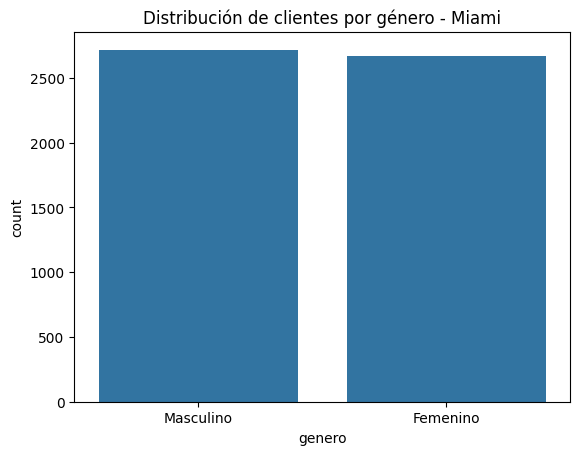

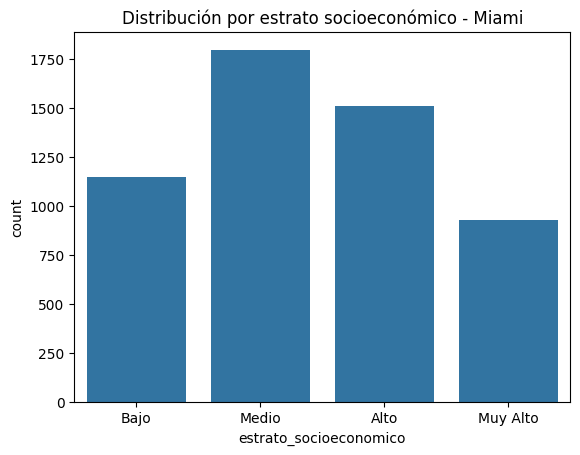

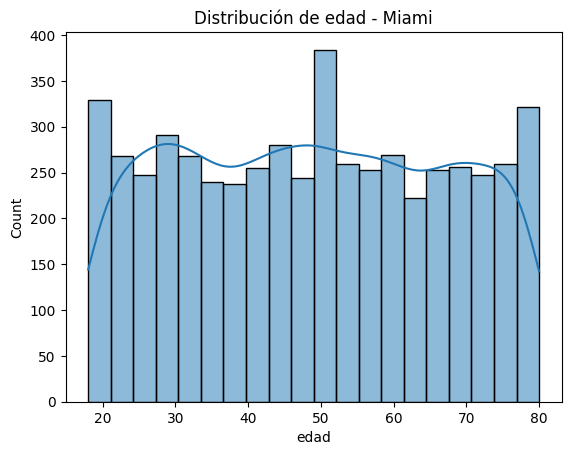

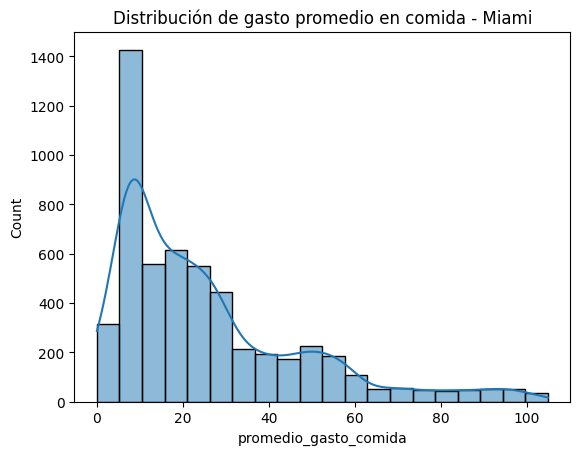

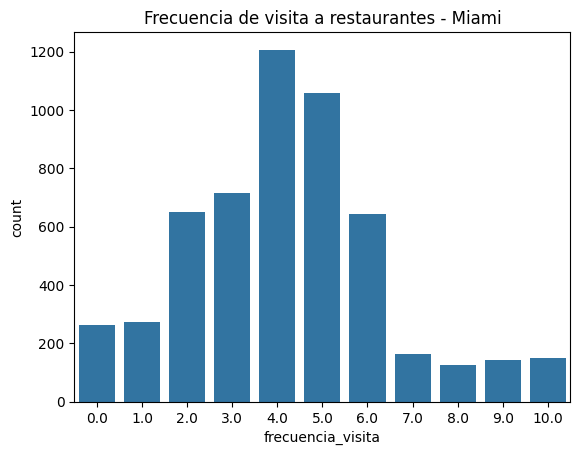

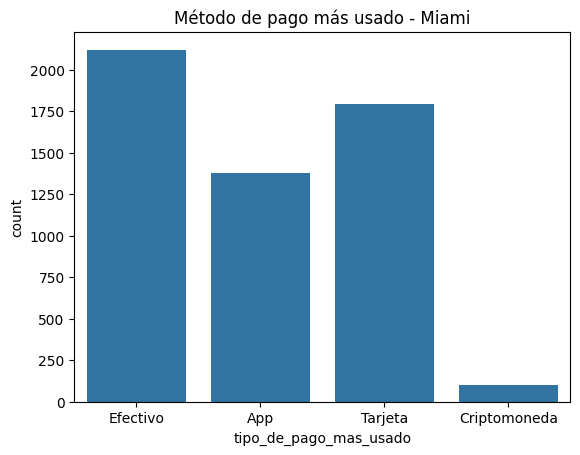

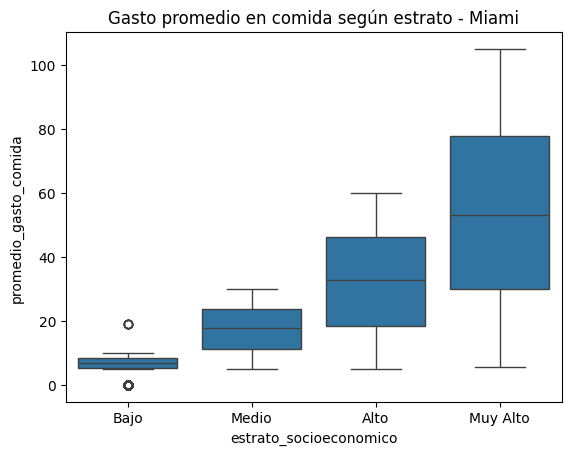

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

# Distribución de género
sns.countplot(data=df_ciudad, x='genero')
plt.title('Distribución de clientes por género - Miami')
plt.show()

# Distribución de estrato socioeconómico
sns.countplot(data=df_ciudad, x='estrato_socioeconomico',
              order=['Bajo','Medio','Alto','Muy Alto'])
plt.title('Distribución por estrato socioeconómico - Miami')
plt.show()

# Distribución de edad
sns.histplot(df_ciudad['edad'], kde=True, bins=20)
plt.title('Distribución de edad - Miami')
plt.show()

# Distribución de gasto promedio en comida
sns.histplot(df_ciudad['promedio_gasto_comida'], kde=True, bins=20)
plt.title('Distribución de gasto promedio en comida - Miami')
plt.show()

# Frecuencia de visita
sns.countplot(data=df_ciudad, x='frecuencia_visita')
plt.title('Frecuencia de visita a restaurantes - Miami')
plt.show()

# Método de pago preferido
sns.countplot(data=df_ciudad, x='tipo_de_pago_mas_usado')
plt.title('Método de pago más usado - Miami')
plt.show()

# Gasto promedio según estrato socioeconómico
sns.boxplot(data=df_ciudad, x='estrato_socioeconomico', y='promedio_gasto_comida',
            order=['Bajo','Medio','Alto','Muy Alto'])
plt.title('Gasto promedio en comida según estrato - Miami')
plt.show()

In [ ]:
df_yelp = pd.read_csv('/content/drive/MyDrive/ProyectoM1_MauricioVazquez/yelp_restaurants.csv')

df_yelp.shape
df_yelp.head()
df_yelp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 463 entries, 0 to 462
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   alias                  463 non-null    object 
 1   title                  463 non-null    object 
 2   id                     463 non-null    object 
 3   name                   463 non-null    object 
 4   price                  463 non-null    object 
 5   rating                 463 non-null    float64
 6   review_count           463 non-null    int64  
 7   distance               463 non-null    float64
 8   coordinates_latitude   463 non-null    float64
 9   coordinates_longitude  463 non-null    float64
 10  location_address1      463 non-null    object 
 11  city                   463 non-null    object 
dtypes: float64(4), int64(1), object(7)
memory usage: 43.5+ KB


In [ ]:
df.columns.tolist()

['alias',
 'title',
 'id',
 'name',
 'price',
 'rating',
 'review_count',
 'distance',
 'coordinates_latitude',
 'coordinates_longitude',
 'location_address1',
 'city']

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/ProyectoM1_MauricioVazquez/base_datos_restaurantes_USA_v2.csv')
df['ciudad_residencia'] = df['ciudad_residencia'].str.strip().str.title()
df['ciudad_residencia'] = df['ciudad_residencia'].replace({'Nyc': 'New York'})

df_yelp = pd.read_csv('/content/drive/MyDrive/ProyectoM1_MauricioVazquez/yelp_restaurants.csv')

print('df (clientes):', df.columns.tolist())
print()
print('df_yelp:', df_yelp.columns.tolist())

df (clientes): ['id_persona', 'nombre', 'apellido', 'edad', 'genero', 'ciudad_residencia', 'estrato_socioeconomico', 'frecuencia_visita', 'promedio_gasto_comida', 'ocio', 'consume_licor', 'preferencias_alimenticias', 'membresia_premium', 'telefono_contacto', 'correo_electronico', 'tipo_de_pago_mas_usado', 'ingresos_mensuales']

df_yelp: ['alias', 'title', 'id', 'name', 'price', 'rating', 'review_count', 'distance', 'coordinates_latitude', 'coordinates_longitude', 'location_address1', 'city']


In [ ]:
distribucion_estrato = df['estrato_socioeconomico'].value_counts()
distribucion_estrato_pct = df['estrato_socioeconomico'].value_counts(normalize=True) * 100

print(distribucion_estrato)
print()
print(distribucion_estrato_pct.round(2))

estrato_socioeconomico
Medio       9325
Alto        9038
Bajo        6161
Muy Alto    5476
Name: count, dtype: int64

estrato_socioeconomico
Medio       31.08
Alto        30.13
Bajo        20.54
Muy Alto    18.25
Name: proportion, dtype: float64


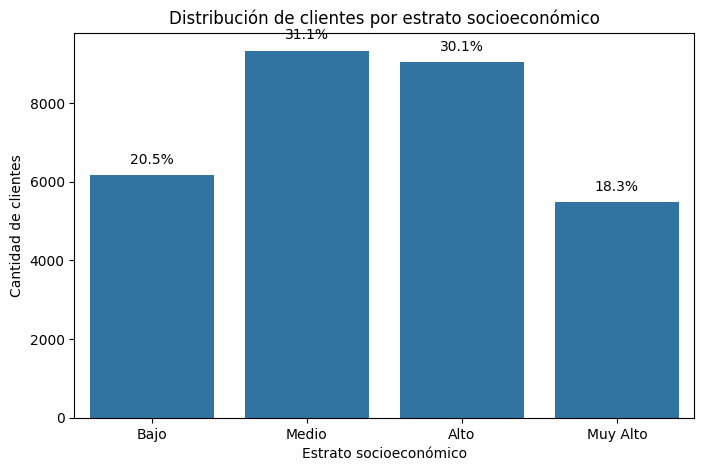

In [ ]:
orden_estrato = ['Bajo', 'Medio', 'Alto', 'Muy Alto']
conteo_estrato = df['estrato_socioeconomico'].value_counts().reindex(orden_estrato)

plt.figure(figsize=(8,5))
ax = sns.barplot(x=conteo_estrato.index, y=conteo_estrato.values, order=orden_estrato)
plt.title('Distribución de clientes por estrato socioeconómico')
plt.xlabel('Estrato socioeconómico')
plt.ylabel('Cantidad de clientes')

# Agregamos el porcentaje encima de cada barra, para lectura inmediata
total = conteo_estrato.sum()
for i, v in enumerate(conteo_estrato.values):
    ax.text(i, v + total*0.01, f'{v/total*100:.1f}%', ha='center', fontsize=10)

plt.show()

ciudad_residencia
Miami        39.82
New York     37.12
Seattle      36.86
Phoenix      36.54
San Diego    34.75
Denver       34.26
Boston       29.49
Dallas       28.70
Houston      26.02
Chicago      25.53
Name: promedio_gasto_comida, dtype: float64


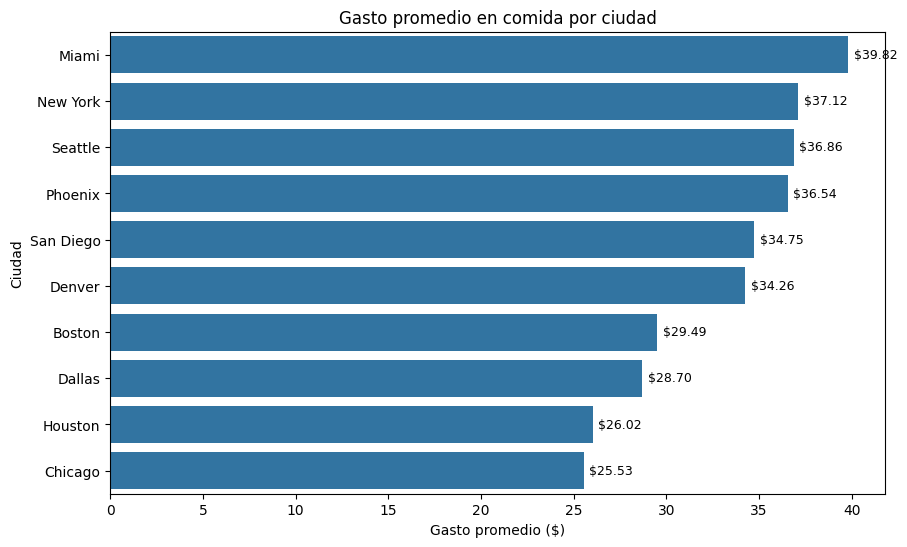

In [ ]:
gasto_por_ciudad = df.groupby('ciudad_residencia')['promedio_gasto_comida'].mean().sort_values(ascending=False)
print(gasto_por_ciudad.round(2))
plt.figure(figsize=(10,6))
ax = sns.barplot(x=gasto_por_ciudad.values, y=gasto_por_ciudad.index, order=gasto_por_ciudad.index)
plt.title('Gasto promedio en comida por ciudad')
plt.xlabel('Gasto promedio ($)')
plt.ylabel('Ciudad')

for i, v in enumerate(gasto_por_ciudad.values):
    ax.text(v + 0.3, i, f'${v:.2f}', va='center', fontsize=9)

plt.show()

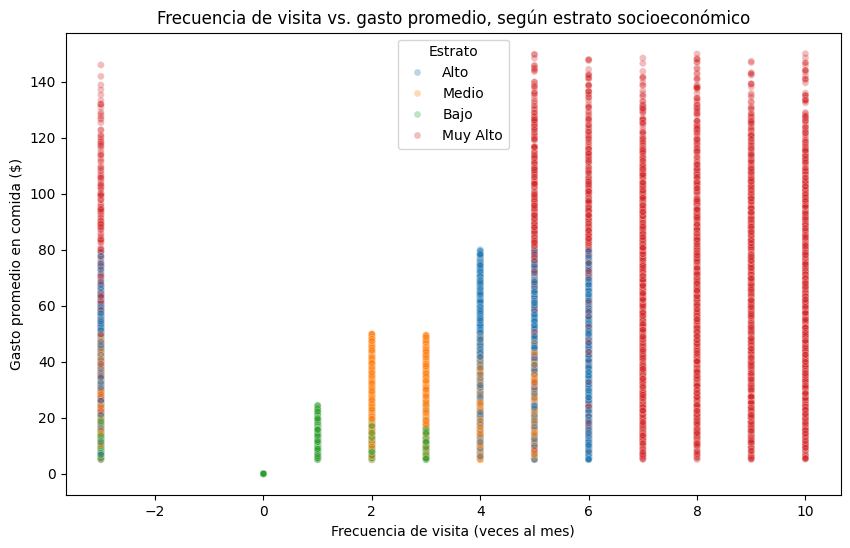

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='frecuencia_visita', y='promedio_gasto_comida',
                 hue='estrato_socioeconomico', alpha=0.3, s=25)
plt.title('Frecuencia de visita vs. gasto promedio, según estrato socioeconómico')
plt.xlabel('Frecuencia de visita (veces al mes)')
plt.ylabel('Gasto promedio en comida ($)')
plt.legend(title='Estrato')
plt.show()

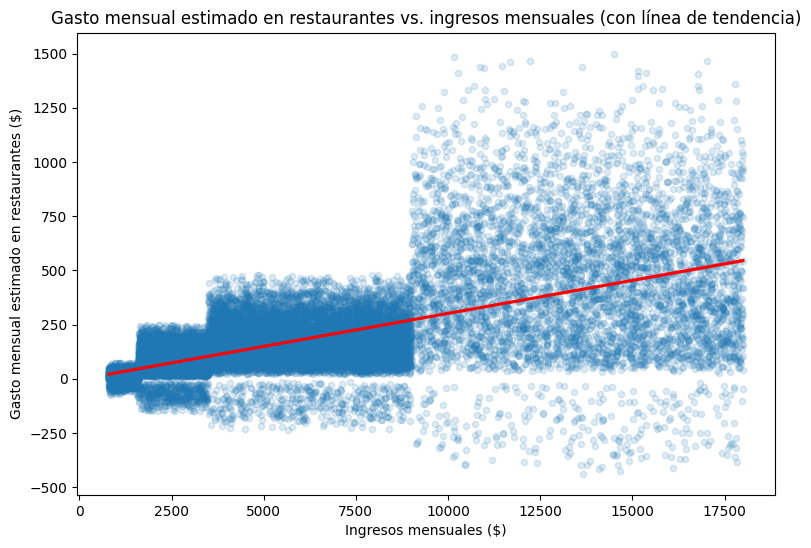

In [ ]:
df['gasto_mensual_estimado'] = df['promedio_gasto_comida'] * df['frecuencia_visita']
plt.figure(figsize=(9,6))
sns.regplot(data=df, x='ingresos_mensuales', y='gasto_mensual_estimado',
            scatter_kws={'alpha':0.15, 's':20}, line_kws={'color':'red'})
plt.title('Gasto mensual estimado en restaurantes vs. ingresos mensuales (con línea de tendencia)')
plt.xlabel('Ingresos mensuales ($)')
plt.ylabel('Gasto mensual estimado en restaurantes ($)')
plt.show()

preferencias_alimenticias  Carnes  Mariscos  Otro  Pescado  Vegano  \
ciudad_residencia                                                    
Boston                       21.9      20.2   8.1     11.1     9.8   
Chicago                      31.1      13.6  11.6     10.7    11.2   
Dallas                       33.2      14.8  10.1      9.7    10.4   
Denver                       26.3      19.5   7.2     10.4    10.7   
Houston                      33.7      15.7  11.2     10.8     9.3   
Miami                        16.8      26.9   9.6     10.1    12.6   
New York                     33.1      17.5   8.7      9.5    12.9   
Phoenix                      29.0      14.6  10.7     13.9    10.8   
San Diego                    22.7      20.2   6.7     10.0    14.1   
Seattle                      25.0      21.1   7.3     10.3    10.1   

preferencias_alimenticias  Vegetariano  
ciudad_residencia                       
Boston                            29.0  
Chicago                           22

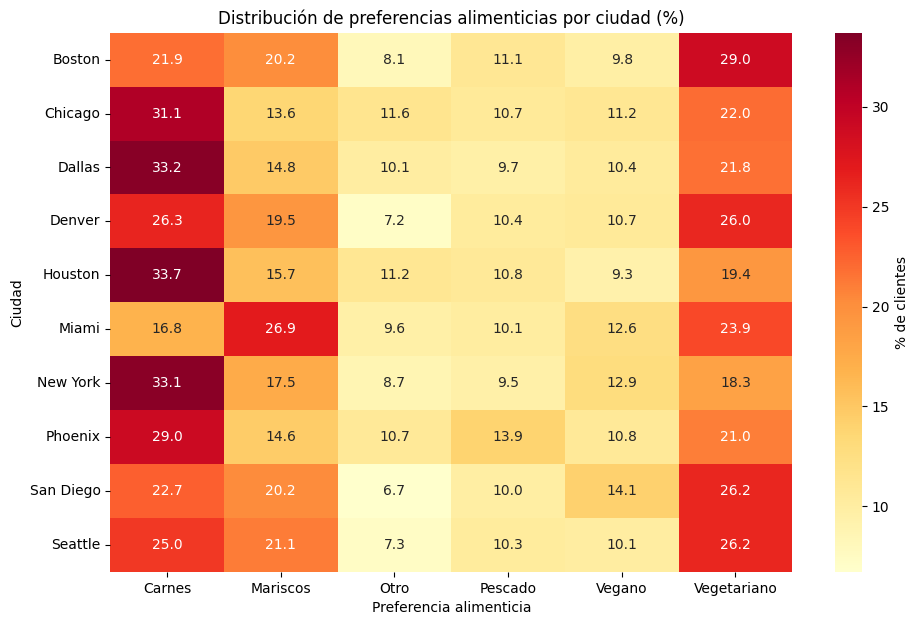

In [ ]:
tabla_preferencias = pd.crosstab(df['ciudad_residencia'], df['preferencias_alimenticias'], normalize='index') * 100
print(tabla_preferencias.round(1))
plt.figure(figsize=(11,7))
sns.heatmap(tabla_preferencias, annot=True, fmt='.1f', cmap='YlOrRd', cbar_kws={'label': '% de clientes'})
plt.title('Distribución de preferencias alimenticias por ciudad (%)')
plt.xlabel('Preferencia alimenticia')
plt.ylabel('Ciudad')
plt.show()

Umbral (percentil 90): 407.02
Cantidad de clientes en este perfil: 2986


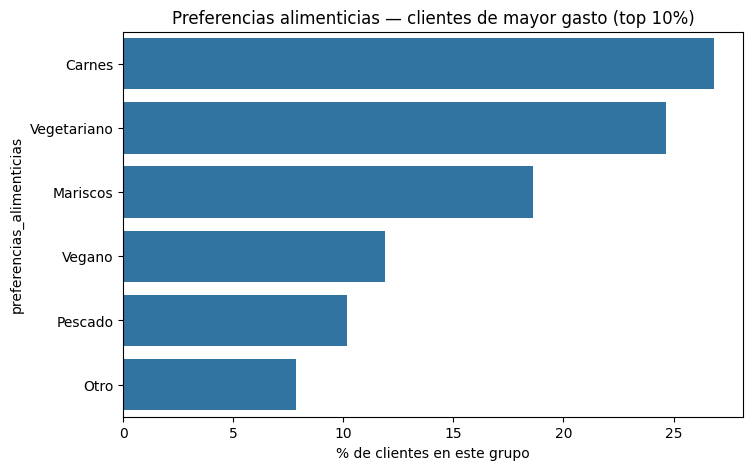

count    2986.000000
mean      677.822445
std       215.449232
min       407.040000
25%       503.902500
50%       627.085000
75%       805.500000
max      1499.700000
Name: gasto_mensual_estimado, dtype: float64
estrato_socioeconomico
Muy Alto    94.340255
Alto         5.659745
Name: proportion, dtype: float64

ciudad_residencia
New York     521
Miami        445
Chicago      410
San Diego    348
Seattle      256
Name: count, dtype: int64


In [ ]:
p90 = df['gasto_mensual_estimado'].quantile(0.90)
top_clientes = df[df['gasto_mensual_estimado'] >= p90]

print('Umbral (percentil 90):', round(p90, 2))
print('Cantidad de clientes en este perfil:', len(top_clientes))
pref_top = top_clientes['preferencias_alimenticias'].value_counts(normalize=True) * 100

plt.figure(figsize=(8,5))
sns.barplot(x=pref_top.values, y=pref_top.index, order=pref_top.index)
plt.title('Preferencias alimenticias — clientes de mayor gasto (top 10%)')
plt.xlabel('% de clientes en este grupo')
plt.show()
print(top_clientes['gasto_mensual_estimado'].describe())
print(top_clientes['estrato_socioeconomico'].value_counts(normalize=True) * 100)
print()
print(top_clientes['ciudad_residencia'].value_counts().head(5))

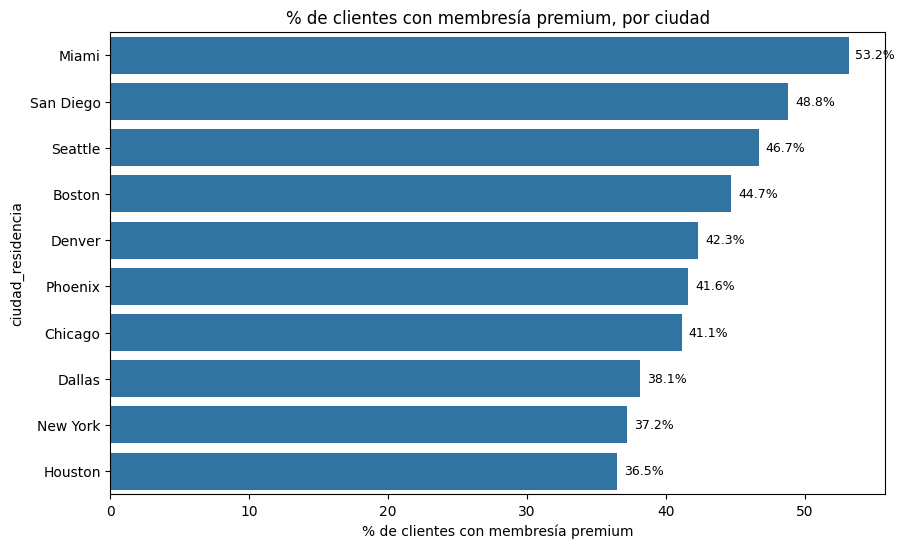

In [ ]:
membresia_proporcion = df.groupby('ciudad_residencia')['membresia_premium'].apply(lambda x: (x=='Sí').mean()*100).sort_values(ascending=False)

plt.figure(figsize=(10,6))
ax = sns.barplot(x=membresia_proporcion.values, y=membresia_proporcion.index, order=membresia_proporcion.index)
plt.title('% de clientes con membresía premium, por ciudad')
plt.xlabel('% de clientes con membresía premium')

for i, v in enumerate(membresia_proporcion.values):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center', fontsize=9)

plt.show()

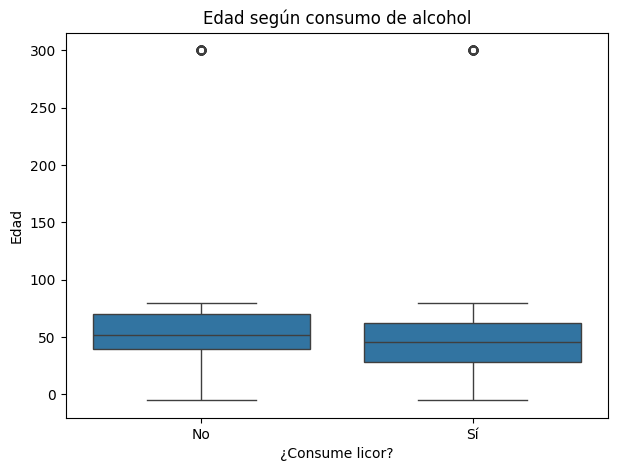

In [ ]:
plt.figure(figsize=(7,5))
sns.boxplot(data=df, x='consume_licor', y='edad')
plt.title('Edad según consumo de alcohol')
plt.xlabel('¿Consume licor?')
plt.ylabel('Edad')
plt.show()

In [ ]:
df_ciudad = df[df['ciudad_residencia'] == 'Miami'].copy()

Demanda (clientes Miami):
preferencias_alimenticias
Mariscos       26.9
Vegetariano    23.9
Carnes         16.8
Vegano         12.6
Pescado        10.1
Otro            9.6
Name: proportion, dtype: float64

Oferta (top 10 categorías Yelp Miami):
title
Seafood           5.2
Cocktail Bars     4.8
New American      4.1
Cuban             3.9
Mediterranean     3.7
Steakhouses       3.5
Italian           3.2
Sandwiches        3.0
Desserts          2.8
Latin American    2.8
Name: proportion, dtype: float64


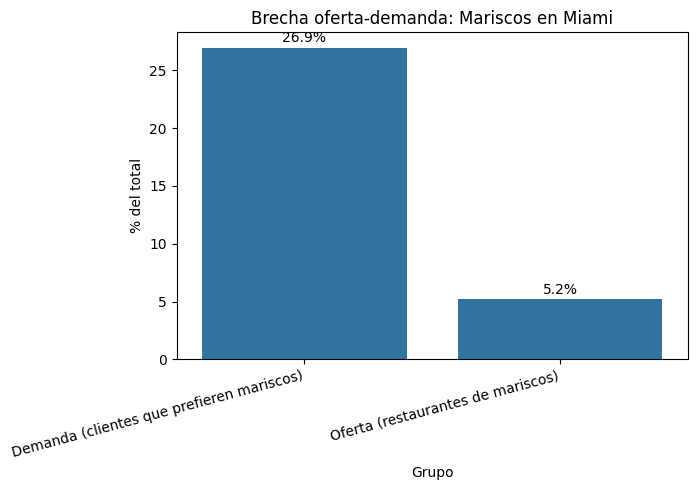

In [ ]:
# Demanda: preferencias de clientes en Miami
demanda = df_ciudad['preferencias_alimenticias'].value_counts(normalize=True) * 100

# Oferta: categorías de restaurantes en Miami (Yelp)
oferta = df_yelp['title'].value_counts(normalize=True).head(10) * 100

print('Demanda (clientes Miami):')
print(demanda.round(1))
print()
print('Oferta (top 10 categorías Yelp Miami):')
print(oferta.round(1))

comparacion = pd.DataFrame({
    'Grupo': ['Demanda (clientes que prefieren mariscos)', 'Oferta (restaurantes de mariscos)'],
    'Porcentaje': [demanda.get('Mariscos', 0), oferta.get('Seafood', 0)]
})

plt.figure(figsize=(7,5))
ax = sns.barplot(data=comparacion, x='Grupo', y='Porcentaje')
plt.title('Brecha oferta-demanda: Mariscos en Miami')
plt.ylabel('% del total')
plt.xticks(rotation=15, ha='right')

for i, v in enumerate(comparacion['Porcentaje']):
    ax.text(i, v + 0.5, f'{v:.1f}%', ha='center', fontsize=10)

plt.tight_layout()
plt.show()

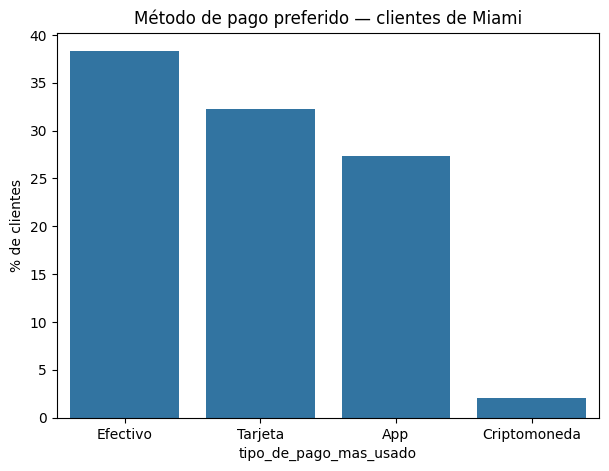

¿Cuál es el método de pago preferido de los clientes de Miami?


In [ ]:
metodo_pago = df_ciudad['tipo_de_pago_mas_usado'].value_counts(normalize=True) * 100

plt.figure(figsize=(7,5))
sns.barplot(x=metodo_pago.index, y=metodo_pago.values, order=metodo_pago.index)
plt.title('Método de pago preferido — clientes de Miami')
plt.ylabel('% de clientes')
plt.show()
print("¿Cuál es el método de pago preferido de los clientes de Miami?")

¿Los restaurantes más populares de Miami son los mejor calificados?


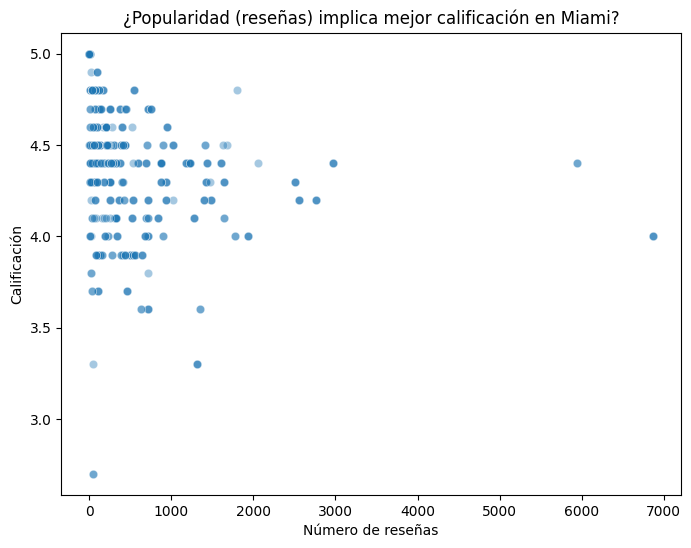

Correlación: -0.182


In [ ]:
print("¿Los restaurantes más populares de Miami son los mejor calificados?")

plt.figure(figsize=(8,6))
sns.scatterplot(data=df_yelp, x='review_count', y='rating', alpha=0.4)
plt.title('¿Popularidad (reseñas) implica mejor calificación en Miami?')
plt.xlabel('Número de reseñas')
plt.ylabel('Calificación')
plt.show()

print('Correlación:', df_yelp['review_count'].corr(df_yelp['rating']).round(3))